# mmBERT + multiple-instance (MIL) head, 120k training rows

## Setup & config

In [1]:
import os, gc, sys, time, math, random, socket, subprocess, warnings, html
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, FileLink, HTML

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

import transformers
from packaging import version
if version.parse(transformers.__version__) < version.parse("4.48.0"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers>=4.48.0"], check=True)
    raise SystemExit("transformers was upgraded: restart the kernel (Run -> Restart) and run again.")
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
print("torch", torch.__version__, "| transformers", transformers.__version__)

# ---------------- config ----------------
QUICK = os.environ.get("QUICK", "0") == "1"    # tiny smoke-test run (set env QUICK=1)

MODEL_NAME    = "jhu-clsp/mmBERT-base"
RANDOM_STATE  = 42          # same seed + split code as the earlier notebooks -> identical validation rows
VAL_N         = 20_000
TRAIN_N       = 120_000     # <- change 2: 4x the previous 30k
BOOST_DOMAINS = ("gutenberg", "arxiv_papers")   # add all human / fusion pool rows of these domains
MAX_LEN       = 1024        # head + tail
HEAD_TOKENS   = 256
EPOCHS        = 1
BATCH_SIZE    = 16          # total over all GPUs
GRAD_ACCUM    = 1
LR            = 3e-5        # backbone
HEAD_LR       = 5e-4        # new layers
WEIGHT_DECAY  = 0.01
WARMUP_RATIO  = 0.06
EVAL_BATCH    = 32
N_EVALS       = 8           # quick checks on MON_N val rows during training
MON_N         = 2000

# change 1: MIL head
WIN          = 32           # tokens per window (instance), roughly one sentence
WIN_STRIDE   = 16
MIL_CH       = 4            # score channels per token; channel 0 gets the MIL loss
MIL_HIDDEN   = 256
MIL_TOPK     = 3
MIL_W        = 0.3          # weight of the MIL max/min loss on channel 0
AUX_W        = 0.2          # weight of the text-only and MIL-only auxiliary heads
HEAD_DROPOUT = 0.1

N_FOLDS_BIAS = 5
SAVE_MODEL   = True         # ~1.2 GB state dict in /kaggle/working, reusable for stacking later

if QUICK:
    VAL_N, TRAIN_N, MAX_LEN, HEAD_TOKENS, MON_N = 1_000, 2_000, 256, 64, 200

TEXT, LANG, DOMAIN, LABEL = "text", "lang", "domain", "label"
CLASSES = ["human", "ai", "fusion"]
LANGS = ["en-EN", "de-DE"]
LABEL2ID = {c: i for i, c in enumerate(CLASSES)}
HUMAN, AI, FUSION = (LABEL2ID[c] for c in CLASSES)

OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPU = torch.cuda.device_count()
if DEVICE.type == "cuda":
    print("GPUs:", [torch.cuda.get_device_name(i) for i in range(N_GPU)])
else:
    print("WARNING: no GPU. Only QUICK mode is usable on CPU.")

@contextmanager
def timer(msg):
    t0 = time.time()
    print(f"[start] {msg} ...", flush=True)
    yield
    print(f"[done]  {msg}: {time.time() - t0:.1f}s", flush=True)

def macro_f1(y, pred):
    return f1_score(y, pred, average="macro")

torch 2.11.0+cu130 | transformers 5.20.2
GPUs: ['Tesla T4', 'Tesla T4']


## Load data & splits
Validation split is identical to the earlier notebooks. Training rows: stratified sample of `TRAIN_N` from the rest, plus all human / fusion rows of the boost domains.

In [2]:
COMP = "ai-generated-text-detection-hw3-ucu-ai-2026"

def find_data_dir():
    for root in [Path("/kaggle/input"), Path("data"), Path("../data"), Path("../../data")]:
        if root.exists():
            hits = sorted(root.rglob("train.csv"))
            hits = [h for h in hits if COMP in str(h)] or hits
            if hits:
                return hits[0].parent
    raise FileNotFoundError("train.csv not found: add the competition data as an input")

DATA_DIR = find_data_dir()
with timer("read csv"):
    train = pd.read_csv(DATA_DIR / "train.csv")
    test = pd.read_csv(DATA_DIR / "test.csv")
    sample_sub = pd.read_csv(next(iter(sorted(DATA_DIR.glob("sample_submission*.csv")))))
for df in (train, test):
    df[TEXT] = df[TEXT].fillna("").astype(str)

strat = train[LABEL] + "|" + train[LANG] + "|" + train[DOMAIN]
pool_idx, val_idx = train_test_split(train.index, test_size=VAL_N, stratify=strat, random_state=RANDOM_STATE)
pool, val = train.loc[pool_idx], train.loc[val_idx]

def strat_sample(df, n, seed=RANDOM_STATE):
    if n is None or n >= len(df):
        return df
    s = df[LABEL] + "|" + df[LANG] + "|" + df[DOMAIN]
    keep, _ = train_test_split(df.index, train_size=n, stratify=s, random_state=seed)
    return df.loc[keep]

trn = strat_sample(pool, TRAIN_N)
boost = pool[pool[DOMAIN].isin(BOOST_DOMAINS) & (pool[LABEL] != "ai")]
boost = boost.loc[boost.index.difference(trn.index)]
trn = pd.concat([trn, boost])
del pool; gc.collect()

y_trn = trn[LABEL].map(LABEL2ID).values
y_val = val[LABEL].map(LABEL2ID).values
print(f"train rows: {len(trn):,} (incl. {len(boost):,} boost rows) | val rows: {len(val):,} | test rows: {len(test):,} | "
      f"val id checksum: {pd.util.hash_pandas_object(val['id'], index=False).sum() % 10**8}")
display(pd.crosstab(trn[DOMAIN], trn[LABEL])[CLASSES])

[start] read csv ...
[done]  read csv: 17.9s
train rows: 121,393 (incl. 1,393 boost rows) | val rows: 20,000 | test rows: 25,000 | val id checksum: 4108583


label,human,ai,fusion
domain,,,
arxiv_papers,377,5309,1698
blog_authorship_corpus,5493,6910,5462
bundestag,6380,8802,7881
cnn_news,5902,8587,5024
euro_court_cases,2766,4909,4477
gutenberg,229,2961,350
house_of_commons,3063,6741,4233
student_essays,5510,9509,8820


## Tokenizer & head + tail inputs
Texts are cut to head + tail right after tokenizing and stored as `int32` arrays, so 120k+ long documents fit in RAM.

In [3]:
def internet_ok(host="huggingface.co", port=443, timeout=3):
    try:
        socket.create_connection((host, port), timeout=timeout).close()
        return True
    except OSError:
        return False

def find_local_model():
    root = Path("/kaggle/input")
    if root.exists():
        for cfg in sorted(root.rglob("config.json")):
            if "mmbert" in str(cfg).lower():
                return str(cfg.parent)
    return None

MODEL_SRC = find_local_model()
if MODEL_SRC is None:
    if not internet_ok():
        raise RuntimeError("No internet and no mmBERT files in /kaggle/input.")
    MODEL_SRC = MODEL_NAME
print("model source:", MODEL_SRC)

tokenizer = AutoTokenizer.from_pretrained(MODEL_SRC)
tokenizer.model_max_length = 10**9

_with = tokenizer("a")["input_ids"]
_without = tokenizer("a", add_special_tokens=False)["input_ids"]
_k = next(i for i in range(len(_with)) if _with[i:i + len(_without)] == _without)
PREFIX, SUFFIX = _with[:_k], _with[_k + len(_without):]
PAD_ID = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
BODY_LEN = MAX_LEN - len(PREFIX) - len(SUFFIX)

def head_tail(ids):
    if len(ids) > BODY_LEN:
        ids = ids[:HEAD_TOKENS] + ids[len(ids) - (BODY_LEN - HEAD_TOKENS):]
    return PREFIX + list(ids) + SUFFIX

def encode_head_tail(texts, batch=2000):
    texts = list(texts)
    out, n_trunc = [], 0
    for i in range(0, len(texts), batch):
        for ids in tokenizer(texts[i:i + batch], add_special_tokens=False, verbose=False)["input_ids"]:
            n_trunc += len(ids) > BODY_LEN
            out.append(np.asarray(head_tail(ids), dtype=np.int32))
    return out, n_trunc / max(len(texts), 1)

with timer("tokenize train / val / test"):
    seqs_trn, tr_trn = encode_head_tail(trn[TEXT])
    seqs_val, tr_val = encode_head_tail(val[TEXT])
    seqs_test, tr_test = encode_head_tail(test[TEXT])
print(f"body tokens/seq: {BODY_LEN} | truncated: train {tr_trn:.1%}, val {tr_val:.1%}, test {tr_test:.1%}")

def pad_batch(seqs):
    L = int(math.ceil(max(len(s) for s in seqs) / 8) * 8)
    ids = torch.full((len(seqs), L), PAD_ID, dtype=torch.long)
    mask = torch.zeros((len(seqs), L), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, :len(s)] = torch.from_numpy(s.astype(np.int64)); mask[i, :len(s)] = 1
    return ids, mask

model source: jhu-clsp/mmBERT-base


config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/46.4k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

[start] tokenize train / val / test ...
[done]  tokenize train / val / test: 124.2s
body tokens/seq: 1022 | truncated: train 18.6%, val 17.8%, test 16.4%


## Model: mmBERT + MIL head
```
                        ┌─ [CLS ‖ mean-pool] ── LayerNorm ─────────────────────────────┐
text ── mmBERT ── h ────┤                                                              ├─ concat ── MLP ── logits (main)
                        └─ token MLP → MIL_CH scores ── window avg (WIN / WIN_STRIDE) ─┤
                                                         bag stats per channel:        │
                                                         max, top-k, mean, min, std,   │
                                                         share>0  ── LayerNorm ────────┘
aux heads: text-only logits, MIL-only logits (AUX_W)  |  MIL loss on channel 0 max / min (MIL_W)
```

In [4]:
class MILFusionClassifier(nn.Module):
    N_STATS = 6   # max, top-k mean, mean, min, std, soft share of positive windows

    def __init__(self, backbone, n_classes=len(CLASSES)):
        super().__init__()
        self.backbone = backbone
        H = backbone.config.hidden_size
        n_mil = MIL_CH * self.N_STATS
        self.text_norm = nn.LayerNorm(2 * H)
        self.tok_scorer = nn.Sequential(nn.Dropout(HEAD_DROPOUT), nn.Linear(H, MIL_HIDDEN), nn.GELU(),
                                        nn.Linear(MIL_HIDDEN, MIL_CH))
        self.mil_norm = nn.LayerNorm(n_mil)
        self.fuse = nn.Sequential(nn.Dropout(HEAD_DROPOUT), nn.Linear(2 * H + n_mil, H), nn.GELU(),
                                  nn.Dropout(HEAD_DROPOUT), nn.Linear(H, n_classes))
        self.text_head = nn.Sequential(nn.Dropout(HEAD_DROPOUT), nn.Linear(2 * H, n_classes))
        self.mil_head = nn.Sequential(nn.Linear(n_mil, 64), nn.GELU(), nn.Linear(64, n_classes))

    @staticmethod
    def window_scores(s, attention_mask):
        # s: (B, K, L) token scores -> (B, K, N) window means over real tokens, valid: (B, 1, N)
        m = attention_mask.float().unsqueeze(1)
        if s.size(-1) < WIN:
            pad = WIN - s.size(-1)
            s, m = F.pad(s, (0, pad)), F.pad(m, (0, pad))
        num = F.avg_pool1d(s * m, WIN, WIN_STRIDE, ceil_mode=True)
        den = F.avg_pool1d(m, WIN, WIN_STRIDE, ceil_mode=True)
        w = num / den.clamp(min=1e-6)
        valid = den >= 0.25                                   # at least a quarter of the window is real text
        valid[..., 0] = valid[..., 0] | ~valid.any(-1)        # every text keeps at least one window
        return w, valid

    @staticmethod
    def bag_stats(w, valid):
        v = valid.float().expand_as(w)
        n = v.sum(-1).clamp(min=1.0)
        w_hi = w.masked_fill(~valid, -1e4)
        w_max = w_hi.amax(-1)
        w_min = w.masked_fill(~valid, 1e4).amin(-1)
        top = w_hi.topk(min(MIL_TOPK, w.size(-1)), dim=-1).values
        tv = (top > -1e3).float()
        top_mean = (top * tv).sum(-1) / tv.sum(-1).clamp(min=1.0)
        mean = (w * v).sum(-1) / n
        std = torch.sqrt(((w - mean.unsqueeze(-1)) ** 2 * v).sum(-1) / n + 1e-6)
        share = (torch.sigmoid(w) * v).sum(-1) / n
        return torch.cat([w_max, top_mean, mean, w_min, std, share], dim=-1), w_max, w_min, w_hi

    def forward(self, input_ids, attention_mask):
        h = self.backbone(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        m = attention_mask.unsqueeze(-1).to(h.dtype)
        mean = (h * m).sum(1) / m.sum(1).clamp(min=1.0)
        text = self.text_norm(torch.cat([h[:, 0], mean], dim=-1).float())
        s = self.tok_scorer(h).float().transpose(1, 2)        # (B, MIL_CH, L), stats in fp32
        w, valid = self.window_scores(s, attention_mask)
        stats, w_max, w_min, w_hi = self.bag_stats(w, valid)
        z = self.mil_norm(stats)
        return (self.fuse(torch.cat([text, z], dim=-1)), self.text_head(text), self.mil_head(z),
                w_max[:, 0], w_min[:, 0], w_hi[:, 0].argmax(-1))

def mil_loss(w_max, w_min, y):
    # channel 0 = window "AI-ness". human: no AI window | ai: no human window | fusion: both kinds present
    t_max = (y != HUMAN).float()
    t_min = (y == AI).float()
    return F.binary_cross_entropy_with_logits(w_max, t_max) + F.binary_cross_entropy_with_logits(w_min, t_min)

bb_kwargs = dict(attn_implementation="sdpa")
try:
    backbone = AutoModel.from_pretrained(MODEL_SRC, reference_compile=False, **bb_kwargs)
except TypeError:
    backbone = AutoModel.from_pretrained(MODEL_SRC, **bb_kwargs)
model = MILFusionClassifier(backbone).to(DEVICE)
net = nn.DataParallel(model) if N_GPU > 1 else model
n_head = sum(p.numel() for n, p in model.named_parameters() if not n.startswith("backbone."))
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M (new head: {n_head / 1e6:.2f}M) | GPUs: {max(N_GPU, 1)}")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.23GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.23GB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] ModernBertModel LOAD REPORT from: jhu-clsp/mmBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
decoder.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


parameters: 308M (new head: 1.41M) | GPUs: 2


## Inference helper

In [5]:
HEADS = ["fused", "text", "mil"]

@torch.no_grad()
def predict_seqs(seqs, batch_size=EVAL_BATCH):
    # returns class probabilities per head + MIL channel-0 max / min logits and the index of the most AI-like window
    net.eval()
    order = np.argsort([len(s) for s in seqs])[::-1]
    out = {k: np.zeros((len(seqs), len(CLASSES)), dtype=np.float32) for k in HEADS}
    out.update(w_max=np.zeros(len(seqs), np.float32), w_min=np.zeros(len(seqs), np.float32),
               top_win=np.zeros(len(seqs), np.int64))
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size].copy()
        ids, mask = pad_batch([seqs[j] for j in idx])
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            res = net(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE))
        for k, lg in zip(HEADS, res[:3]):
            out[k][idx] = F.softmax(lg.float(), dim=-1).cpu().numpy()
        out["w_max"][idx] = res[3].float().cpu().numpy()
        out["w_min"][idx] = res[4].float().cpu().numpy()
        out["top_win"][idx] = res[5].cpu().numpy()
    return out

## Fine-tune
AdamW, linear warmup / decay, fp16 + GradScaler, length-grouped batches. Separate LR for the new layers. Loss = CE(fused) + `AUX_W`·(CE(text) + CE(MIL)) + `MIL_W`·MIL max/min loss.

optimizer steps: 7,588 (batch 16 x accum 1)
epoch 1 step 50/7588 | loss 1.8359 | mil 1.2363 | lr 3.30e-06 | 8,861 tok/s | elapsed 0.8 min | ETA 114.3 min
epoch 1 step 100/7588 | loss 1.2243 | mil 0.7002 | lr 6.59e-06 | 9,976 tok/s | elapsed 1.4 min | ETA 106.2 min
epoch 1 step 150/7588 | loss 0.8147 | mil 0.3980 | lr 9.89e-06 | 10,553 tok/s | elapsed 2.1 min | ETA 104.8 min
epoch 1 step 200/7588 | loss 0.7322 | mil 0.3529 | lr 1.32e-05 | 10,698 tok/s | elapsed 2.8 min | ETA 102.0 min
epoch 1 step 250/7588 | loss 0.6498 | mil 0.3358 | lr 1.65e-05 | 11,033 tok/s | elapsed 3.5 min | ETA 102.9 min
epoch 1 step 300/7588 | loss 0.6289 | mil 0.3448 | lr 1.98e-05 | 11,081 tok/s | elapsed 4.2 min | ETA 101.0 min
epoch 1 step 350/7588 | loss 0.6762 | mil 0.3854 | lr 2.31e-05 | 11,176 tok/s | elapsed 4.9 min | ETA 100.6 min
epoch 1 step 400/7588 | loss 0.6270 | mil 0.3582 | lr 2.64e-05 | 11,222 tok/s | elapsed 5.5 min | ETA 99.4 min
epoch 1 step 450/7588 | loss 0.6664 | mil 0.4113 | lr 2.97e-05 |

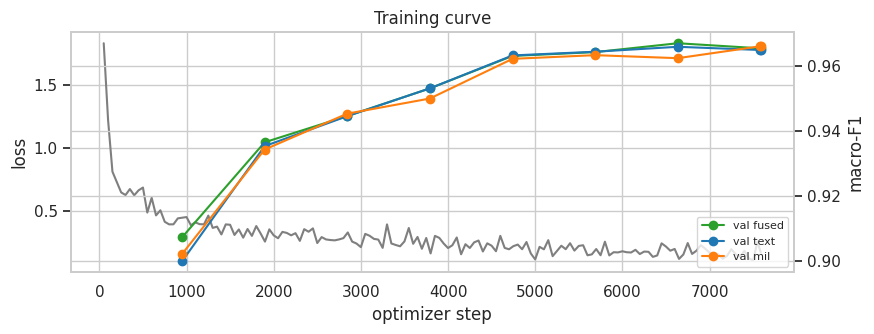

In [6]:
def length_grouped_batches(lengths, batch_size, rng, mega=50):
    idx = rng.permutation(len(lengths))
    batches = []
    for i in range(0, len(idx), batch_size * mega):
        group = sorted(idx[i:i + batch_size * mega], key=lambda j: lengths[j])
        batches += [group[k:k + batch_size] for k in range(0, len(group), batch_size)]
    rng.shuffle(batches)
    return batches

no_decay = ("bias", "norm")
bb = list(model.backbone.named_parameters())
head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone.")]
optimizer = torch.optim.AdamW([
    {"params": [p for n, p in bb if not any(k in n.lower() for k in no_decay)], "lr": LR, "weight_decay": WEIGHT_DECAY},
    {"params": [p for n, p in bb if any(k in n.lower() for k in no_decay)], "lr": LR, "weight_decay": 0.0},
    {"params": head_params, "lr": HEAD_LR, "weight_decay": WEIGHT_DECAY},
])
steps_per_epoch = math.ceil(len(seqs_trn) / BATCH_SIZE / GRAD_ACCUM)
total_steps = steps_per_epoch * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
use_amp = DEVICE.type == "cuda"
try:
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

rng = np.random.default_rng(RANDOM_STATE)
mon_idx = rng.choice(len(val), size=min(MON_N, len(val)), replace=False)
mon_seqs = [seqs_val[i] for i in mon_idx]
eval_every = max(total_steps // N_EVALS, 1)
lengths = [len(s) for s in seqs_trn]
history, step, t_start, n_tok = [], 0, time.time(), 0
print(f"optimizer steps: {total_steps:,} (batch {BATCH_SIZE} x accum {GRAD_ACCUM})")

for epoch in range(EPOCHS):
    batches = length_grouped_batches(lengths, BATCH_SIZE, rng)
    net.train()
    running, run_mil, n_since = 0.0, 0.0, 0
    for b_i, batch in enumerate(batches):
        batch = np.asarray(batch)
        ids, mask = pad_batch([seqs_trn[j] for j in batch])
        labels = torch.tensor(y_trn[batch], device=DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            lg_fused, lg_text, lg_mil, w_max, w_min, _ = net(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE))
        l_mil = mil_loss(w_max.float(), w_min.float(), labels)
        loss = (F.cross_entropy(lg_fused.float(), labels)
                + AUX_W * (F.cross_entropy(lg_text.float(), labels) + F.cross_entropy(lg_mil.float(), labels))
                + MIL_W * l_mil) / GRAD_ACCUM
        scaler.scale(loss).backward()
        running += loss.item() * GRAD_ACCUM; run_mil += l_mil.item(); n_tok += int(mask.sum())
        if (b_i + 1) % GRAD_ACCUM == 0 or b_i == len(batches) - 1:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); scheduler.step()
            step += 1; n_since += 1
            if step % 50 == 0 or step == total_steps:
                el = time.time() - t_start
                print(f"epoch {epoch + 1} step {step}/{total_steps} | loss {running / n_since:.4f} | "
                      f"mil {run_mil / n_since / GRAD_ACCUM:.4f} | lr {scheduler.get_last_lr()[0]:.2e} | "
                      f"{n_tok / el:,.0f} tok/s | elapsed {el / 60:.1f} min | ETA {el / step * (total_steps - step) / 60:.1f} min",
                      flush=True)
                history.append({"step": step, "loss": running / n_since})
                running, run_mil, n_since = 0.0, 0.0, 0
            if step % eval_every == 0 or step == total_steps:
                p = predict_seqs(mon_seqs)
                r = {f"val_mon_{k}": macro_f1(y_val[mon_idx], p[k].argmax(1)) for k in HEADS}
                history.append({"step": step, **r})
                print("   -> val monitor macro-F1 | " + " | ".join(f"{k}: {v:.4f}" for k, v in r.items()), flush=True)
                net.train()
print(f"training done in {(time.time() - t_start) / 60:.1f} min")

hist = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(9, 3.5))
h = hist.dropna(subset=["loss"]); ax.plot(h["step"], h["loss"], label="train loss", c="tab:gray")
ax2 = ax.twinx()
for k, c in zip(HEADS, ["tab:green", "tab:blue", "tab:orange"]):
    col = f"val_mon_{k}"
    if col in hist:
        hh = hist.dropna(subset=[col]); ax2.plot(hh["step"], hh[col], "o-", c=c, label=f"val {k}")
ax2.set_ylabel("macro-F1"); ax2.legend(loc="lower right", fontsize=8)
ax.set_xlabel("optimizer step"); ax.set_ylabel("loss"); ax.set_title("Training curve"); plt.tight_layout(); plt.show()

if SAVE_MODEL:
    torch.save(model.state_dict(), OUT_DIR / "mmbert_mil.pt")

## Validation: fused vs text-only vs MIL-only
All three heads come from the same network. `text` is the plain [CLS ‖ mean] classifier (closest to earlier runs), `mil` uses only the window statistics.

In [7]:
with timer("predict val"):
    val_p = predict_seqs(seqs_val)

rows = []
for k in HEADS:
    pred = val_p[k].argmax(1)
    rows.append({"head": k, "macro_f1": macro_f1(y_val, pred), "accuracy": accuracy_score(y_val, pred),
                 **{f"f1_{c}": v for c, v in zip(CLASSES, f1_score(y_val, pred, average=None, labels=range(3)))}})
display(pd.DataFrame(rows).style.background_gradient(subset=["macro_f1", "f1_human", "f1_ai", "f1_fusion"], cmap="Greens")
        .format(precision=4))
print("reference (previous notebook): fused 0.9596 | text 0.9542 | stacker 0.9638")

[start] predict val ...
[done]  predict val: 258.6s


,head,macro_f1,accuracy,f1_human,f1_ai,f1_fusion
0,fused,0.9672,0.9724,0.9482,0.9964,0.9569
1,text,0.9668,0.9721,0.9476,0.9964,0.9564
2,mil,0.9669,0.9721,0.9480,0.9962,0.9565


reference (previous notebook): fused 0.9596 | text 0.9542 | stacker 0.9638


### Does channel 0 behave like a window AI-score?
Expected: human → max and min low, ai → both high, fusion → max high and min low.

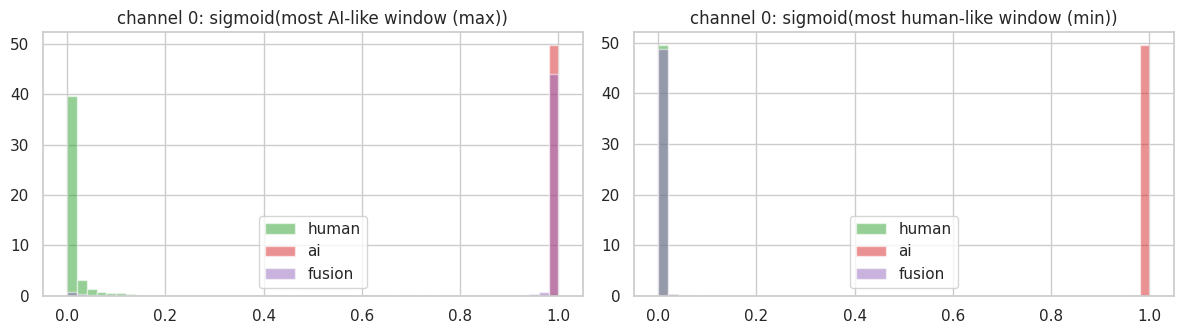

In [8]:
sig = lambda x: 1 / (1 + np.exp(-x))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, key, title in zip(axes, ["w_max", "w_min"], ["most AI-like window (max)", "most human-like window (min)"]):
    for c, col in zip(CLASSES, ["tab:green", "tab:red", "tab:purple"]):
        ax.hist(sig(val_p[key][y_val == LABEL2ID[c]]), bins=50, alpha=0.5, density=True, label=c, color=col)
    ax.set_title(f"channel 0: sigmoid({title})"); ax.legend()
plt.tight_layout(); plt.show()

### Fusion examples: the window the MIL head finds most AI-like (highlighted)

In [9]:
def show_top_window(i, context=60):
    s = seqs_val[i]
    a = int(val_p["top_win"][i]) * WIN_STRIDE
    b = min(a + WIN, len(s))
    dec = lambda x: html.escape(tokenizer.decode(x.tolist(), skip_special_tokens=True))
    lo = max(len(PREFIX), a - context)
    return (f"<p><b>{val[DOMAIN].iloc[i]}</b> | true={CLASSES[y_val[i]]} | pred={CLASSES[val_p['fused'][i].argmax()]} | "
            f"window AI-score={sig(val_p['w_max'][i]):.2f}<br>…{dec(s[lo:a])}"
            f"<mark>{dec(s[a:b])}</mark>{dec(s[b:b + context])}…</p>")

fus = np.where(y_val == FUSION)[0]
pick = np.random.default_rng(0).choice(fus, size=min(6, len(fus)), replace=False)
display(HTML("".join(show_top_window(i) for i in pick)))

### Class-bias tuning for macro-F1 (nested)
Per-class offsets on the log-probabilities (human fixed at 0), tuned on 4 folds and applied to the 5th, so the score is honest. Offsets for test are tuned on all validation rows.

In [10]:
def fast_macro_f1(y, pred, k=len(CLASSES)):
    cm = np.bincount(y * k + pred, minlength=k * k).reshape(k, k)
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    return float(np.mean(2 * tp / np.maximum(2 * tp + fp + fn, 1)))

GRID = np.round(np.arange(-1.0, 1.0001, 0.05), 3)
def tune_bias(P, y):
    L = np.log(P + 1e-7)
    best, best_b = fast_macro_f1(y, L.argmax(1)), np.zeros(3)
    for a in GRID:
        for b in GRID:
            s = fast_macro_f1(y, (L + np.array([0.0, a, b])).argmax(1))
            if s > best + 1e-9:
                best, best_b = s, np.array([0.0, a, b])
    return best_b

def apply_bias(P, b):
    return (np.log(P + 1e-7) + b).argmax(1)

skf = StratifiedKFold(n_splits=N_FOLDS_BIAS, shuffle=True, random_state=RANDOM_STATE)
FOLDS = list(skf.split(np.zeros(len(val)), (val[LABEL] + "|" + val[DOMAIN]).values))

def nested_bias_pred(P, y):
    pred = np.zeros(len(y), dtype=int)
    for tr, te in FOLDS:
        pred[te] = apply_bias(P[te], tune_bias(P[tr], y[tr]))
    return pred

cands = {"fused": val_p["fused"],
         "mean of 3 heads": (val_p["fused"] + val_p["text"] + val_p["mil"]) / 3}
rows = []
for name, P in cands.items():
    for bias in (False, True):
        pred = nested_bias_pred(P, y_val) if bias else P.argmax(1)
        rows.append({"pipeline": name, "bias_tuned": bias, "macro_f1": macro_f1(y_val, pred),
                     **{f"f1_{c}": v for c, v in zip(CLASSES, f1_score(y_val, pred, average=None, labels=range(3)))},
                     **{f"macro_f1_{l}": macro_f1(y_val[(val[LANG] == l).values], pred[(val[LANG] == l).values]) for l in LANGS}})
res = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(res.style.background_gradient(subset=[c for c in res.columns if c.startswith(("macro", "f1_"))], cmap="Greens")
        .format(precision=4))

BEST_NAME, BEST_BIAS = res.loc[0, "pipeline"], bool(res.loc[0, "bias_tuned"])
best_val_pred = nested_bias_pred(cands[BEST_NAME], y_val) if BEST_BIAS else cands[BEST_NAME].argmax(1)
print(f"best: {BEST_NAME} | bias tuned: {BEST_BIAS} | val macro-F1 = {res.loc[0, 'macro_f1']:.4f}\n")
print(classification_report(y_val, best_val_pred, target_names=CLASSES, digits=4))

,pipeline,bias_tuned,macro_f1,f1_human,f1_ai,f1_fusion,macro_f1_en-EN,macro_f1_de-DE
0,fused,False,0.9672,0.9482,0.9964,0.9569,0.9630,0.9823
1,mean of 3 heads,False,0.9670,0.9478,0.9964,0.9567,0.9627,0.9825
2,mean of 3 heads,True,0.9667,0.9471,0.9963,0.9565,0.9623,0.9825
3,fused,True,0.9660,0.9460,0.9964,0.9556,0.9615,0.9823


best: fused | bias tuned: False | val macro-F1 = 0.9672

              precision    recall  f1-score   support

       human     0.9310    0.9661    0.9482      4900
          ai     0.9964    0.9963    0.9964      8954
      fusion     0.9717    0.9426    0.9569      6146

    accuracy                         0.9724     20000
   macro avg     0.9664    0.9683    0.9672     20000
weighted avg     0.9728    0.9724    0.9724     20000



### Confusion matrices and per-domain scores
`h→f` / `f→h`: share of true human predicted fusion and vice versa.

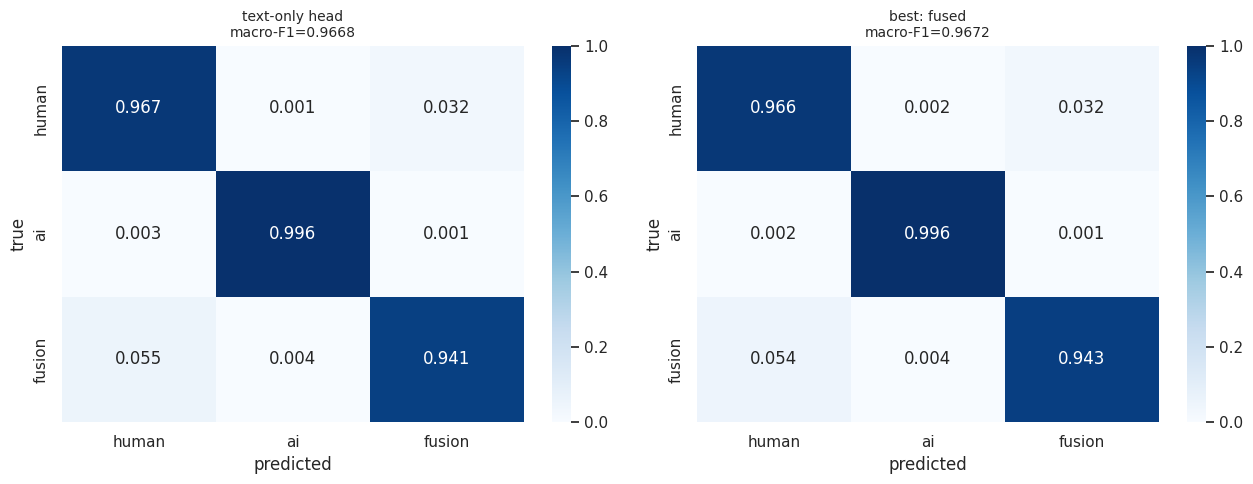

,lang,domain,n,text_only,best,h→f,f→h,delta
6,en-EN,gutenberg,508,0.8219,0.8219,0.3125,0.2000,0.0000
2,en-EN,arxiv_papers,1050,0.8666,0.8666,0.3333,0.0667,0.0000
3,en-EN,blog_authorship_corpus,2977,0.9143,0.9153,0.0689,0.1396,0.0010
5,en-EN,euro_court_cases,2025,0.9322,0.9338,0.0803,0.1046,0.0016
7,en-EN,house_of_commons,2340,0.9818,0.9818,0.0196,0.0297,0.0000
0,de-DE,bundestag,3844,0.9822,0.9822,0.0094,0.0335,0.0000
8,en-EN,student_essays,3973,0.9849,0.9849,0.0207,0.0204,0.0000
4,en-EN,cnn_news,3252,0.9927,0.9927,0.0041,0.0179,0.0000
1,de-DE,gutenberg,31,1.0000,1.0000,0.0000,0.0000,0.0000


In [11]:
base_pred = val_p["text"].argmax(1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, pred) in zip(axes, [("text-only head", base_pred), (f"best: {BEST_NAME}", best_val_pred)]):
    cm = confusion_matrix(y_val, pred, labels=range(3))
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f"{name}\nmacro-F1={macro_f1(y_val, pred):.4f}", fontsize=10); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

v = val.assign(base=base_pred, best=best_val_pred, y=y_val)
def rate(g, t, p):
    m = g["y"] == t
    return (g.loc[m, "best"] == p).mean() if m.any() else np.nan
dom = pd.DataFrame([{"lang": l, "domain": d, "n": len(g), "text_only": macro_f1(g["y"], g["base"]),
                     "best": macro_f1(g["y"], g["best"]), "h→f": rate(g, HUMAN, FUSION), "f→h": rate(g, FUSION, HUMAN)}
                    for (l, d), g in v.groupby([LANG, DOMAIN])]).assign(delta=lambda x: x["best"] - x["text_only"])
display(dom.sort_values("best").style.background_gradient(subset=["delta"], cmap="RdYlGn", vmin=-0.05, vmax=0.05)
        .format(precision=4))

## Predict test & save submission
Also saves raw probabilities and MIL statistics (`probs_mmbert_mil.npz`) for later ensembling / stacking.

In [12]:
with timer("predict test"):
    test_p = predict_seqs(seqs_test)

test_cands = {"fused": test_p["fused"], "mean of 3 heads": (test_p["fused"] + test_p["text"] + test_p["mil"]) / 3}
test_P = test_cands[BEST_NAME]
if BEST_BIAS:
    bias = tune_bias(cands[BEST_NAME], y_val)
    print("class offsets (human, ai, fusion):", bias)
    test_pred_id = apply_bias(test_P, bias)
else:
    test_pred_id = test_P.argmax(1)
test_pred = np.array(CLASSES)[test_pred_id]

sub = sample_sub[["id"]].merge(pd.DataFrame({"id": test["id"].values, "label": test_pred}), on="id", how="left")
assert sub["label"].notna().all() and len(sub) == len(sample_sub) and set(sub["label"]) <= set(CLASSES)
SUB_PATH = OUT_DIR / "submission.csv"
sub.to_csv(SUB_PATH, index=False)
print(f"pipeline: {BEST_NAME} (bias={BEST_BIAS}) | saved {SUB_PATH.resolve()} {sub.shape}")

np.savez_compressed(OUT_DIR / "probs_mmbert_mil.npz",
                    val_ids=val["id"].values, test_ids=test["id"].values, val_best=cands[BEST_NAME], test_best=test_P,
                    **{f"val_{k}": val_p[k] for k in HEADS + ["w_max", "w_min"]},
                    **{f"test_{k}": test_p[k] for k in HEADS + ["w_max", "w_min"]})

display(sub.head())
display(pd.concat({"train share": train[LABEL].value_counts(normalize=True),
                   "val pred share": pd.Series(np.array(CLASSES)[best_val_pred]).value_counts(normalize=True),
                   "test pred share": sub["label"].value_counts(normalize=True)}, axis=1).loc[CLASSES].round(3))
os.chdir(OUT_DIR)
display(FileLink(SUB_PATH.name))

[start] predict test ...
[done]  predict test: 321.0s
pipeline: fused (bias=False) | saved /kaggle/working/submission.csv (25000, 2)


,id,label
0,8ff2d1,ai
1,a261cf,human
2,ad5614,fusion
3,3a23ac,ai
4,28b4e5,ai


,train share,val pred share,test pred share
human,0.245,0.254,0.262
ai,0.448,0.448,0.513
fusion,0.307,0.298,0.224


/kaggle/working/submission.csv